# 멀티모달 RAG — 논문 PDF의 텍스트·표·그림으로 답하기

| 항목 | 내용 |
|---|---|
| 분석 PDF | `data/invest.pdf` — Song & Ermon, *Generative Modeling by Estimating Gradients of the Data Distribution* (arXiv:1907.05600, 23쪽) |
| 준비물 | OpenAI API 키(`.env`), Poppler, Tesseract |
| 결과물 | 한국어로 질문하면 논문의 텍스트·표·그림을 찾아 근거와 함께 답하는 RAG |

**사용법**: 위에서부터 셀을 하나씩 `Shift + Enter`로 실행하고, **출력이 남은 상태로 저장**한 뒤 커밋합니다.

## 목차

| 파트 | 내용 | 셀 |
|---|---|---|
| 0 | 전체 그림 | 개념 |
| 1 | 환경 준비 (임포트·API 키·설정값) | [1]~[3] |
| 2 | 1단계 추출: 텍스트 / 표 / 그림 | [4]~[6] |
| 3 | 2단계 요약: 텍스트·표·그림 요약 | [7]~[8] |
| 4 | 3단계 검색기: 요약 검색 → 원본 반환 | [9] |
| 5 | LangChain 체인: 번역 체인 / RAG 체인 | [10]~[11] |
| 6 | 전체 파이프라인 & 질의응답 5건 | [12]~[14] |
| 7 | Before / After: 텍스트 RAG vs 멀티모달 RAG | [15]~[16] |

---
# Part 0. 전체 그림

### 사전 준비 단계 (최초 1회)
```
 data/invest.pdf ──[1단계] partition_pdf(hi_res)──▶ 텍스트 블록 / 표(HTML) / 그림(data/figures/*.jpg)
                                                       │
                                     [2단계] 요약 (gpt-4o-mini, 그림은 비전 입력)
                                                       ▼
                    요약 ──▶ Chroma (검색용)      원본 ──▶ InMemoryStore (답변용)      ← doc_id 로 연결
```

### 질문할 때
```
 사용자(한국어) "Table 1에서 NCSN보다 점수가 높은 모델은?"
        │  ① 번역 체인                         ← LangChain LCEL
        ▼
 "Which model scores higher than NCSN in Table 1?"
        │  ② 요약 임베딩 검색 → doc_id 로 원본 꺼내기     ← Retrieval
        ▼
 [table p.7] <table>...</table>,  [image p.4] (base64) ...
        │  ③ 원본 텍스트·표 + 그림(data URL)으로 프롬프트 구성  ← Augmentation
        │  ④ RAG 체인 (gpt-4o-mini 비전)                   ← Generation
        │  ⑤ 번역 체인
        ▼
 한국어 답변 + 근거(종류·페이지) + 검색된 그림
```

### 왜 요약으로 검색하고 원본으로 생성하나?
- 표 HTML은 태그·숫자 위주라 그대로 임베딩하면 의미가 잘 안 잡히고, 그림은 텍스트 임베딩을 할 수 없습니다 → **요약(문장)으로 검색**
- 요약은 수치·세부가 빠질 수 있습니다 → **답변은 원본(표 전체, 그림 자체)으로 생성**

---
# Part 1. 환경 준비

In [29]:
# ============================================================
# [1] 라이브러리 임포트 & 환경 점검
# ============================================================
import os
import shutil
import sys
import time
from collections import Counter
from pathlib import Path

from dotenv import load_dotenv

# 프로젝트 루트(src/extract.py 가 있는 폴더)를 찾아 이동하고, src/ 를 임포트할 수 있게 합니다.
# 실행 위치(현재 폴더)가 notebooks/ 가 아니어도 동작하도록 노트북 파일 위치와 상위 폴더까지 찾습니다.
def find_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents]
    notebook_file = os.environ.get("JPY_SESSION_NAME") or globals().get("__vsc_ipynb_file__")
    if notebook_file:
        nb_dir = Path(notebook_file).resolve().parent
        candidates = [nb_dir, *nb_dir.parents] + candidates
    for path in candidates:
        if (path / "src" / "extract.py").exists():
            return path
    raise FileNotFoundError(f"src/extract.py 를 찾지 못했습니다. 현재 위치: {Path.cwd()}")


PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("프로젝트 루트:", PROJECT_ROOT)

# --- LangChain ---
from langchain_core.messages import HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_openai import ChatOpenAI

# --- 이미지 처리 & 노트북 출력 ---
from IPython.display import Markdown, display
from PIL import Image

# --- 프로젝트 모듈 (src/) ---
from src.extract import (categorize_elements, extract_pdf_elements, list_figures,
                         load_pickle, save_pickle)
from src.retriever import create_multi_vector_retriever
from src.summarize import summarize_elements, summarize_images

print("Python   :", sys.version.split()[0], "/", sys.prefix)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
for mod in ["unstructured", "unstructured_inference", "langchain_classic", "chromadb", "tiktoken"]:
    try:
        __import__(mod)
        print(f"{mod:22s}: OK")
    except ImportError:
        print(f"{mod:22s}: ✗ 미설치")

프로젝트 루트: C:\workspaces\multimodal-rag
Python   : 3.11.9 / c:\workspaces\multimodal-rag\.venv
Poppler  : OK
Tesseract: OK
unstructured          : OK
unstructured_inference: OK
langchain_classic     : OK
chromadb              : OK
tiktoken              : OK


In [30]:
# ============================================================
# [2] OpenAI API 키 설정
# ============================================================
load_dotenv()                                   # .env 파일을 찾아 환경변수로 등록
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")    # 환경변수에서 키 읽기 (없으면 None)

if not OPENAI_API_KEY:
    raise ValueError("OPENAI_API_KEY 가 설정되지 않았습니다. .env 파일을 확인하세요.")

# 키 전체를 출력하면 보안상 위험하므로 앞 4자리만 확인용으로 출력
print("API 키 설정 완료:", OPENAI_API_KEY[:4] + "****")

API 키 설정 완료: sk-p****


In [31]:
# ============================================================
# [3] 설정값 (한 곳에서 관리)
# ============================================================
PDF_PATH      = PROJECT_ROOT / "data" / "invest.pdf"
FIGURES_DIR   = PROJECT_ROOT / "data" / "figures"      # 추출된 그림 저장 위치
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"    # 추출·요약 결과 저장 (Git 제외)

SUMMARY_MODEL     = "gpt-4o-mini"   # 텍스트·표·그림 요약 (비전 입력 지원)
RAG_MODEL         = "gpt-4o-mini"   # 원본 텍스트·표·그림을 보고 답변
TRANSLATION_MODEL = "gpt-4o-mini"   # 한↔영 번역
N_RESULTS         = 6               # 질문 하나당 검색할 벡터 수 (같은 원본은 하나로 합쳐짐)

REBUILD = False   # True 로 바꾸면 저장본을 무시하고 추출·요약을 처음부터 다시 실행

print("PDF 존재 여부:", PDF_PATH.exists(), PDF_PATH)
print("그림 폴더    :", FIGURES_DIR)

PDF 존재 여부: True C:\workspaces\multimodal-rag\data\invest.pdf
그림 폴더    : C:\workspaces\multimodal-rag\data\figures


---
# Part 2. 1단계 추출 — 텍스트 · 표 · 그림 (수업 01)

| 옵션 | 값 | 빼면 생기는 일 |
| --- | --- | --- |
| `strategy` | `"hi_res"` | 표·그림 영역을 인식하지 못함 |
| `extract_images_in_pdf` | `True` | 그림이 통째로 사라짐 |
| `infer_table_structure` | `True` | Table 1이 줄글로 뭉개짐 |
| `chunking_strategy` | `"by_title"` (4000 / 3800 / 2000) | 섹션 의미가 끊긴 블록이 생김 |

> ⏱️ hi_res는 몇 분 걸립니다. 결과는 `data/processed/extracted.pkl`에 저장되고, 다음부터는 저장본을 불러옵니다.

In [32]:
# ============================================================
# [4] 추출 실행 (저장본이 있으면 불러옴)
# ============================================================
EXTRACTED_PKL = PROCESSED_DIR / "extracted.pkl"

if EXTRACTED_PKL.exists() and not REBUILD:
    data = load_pickle(EXTRACTED_PKL)
    print("저장본 불러옴:", EXTRACTED_PKL)
else:
    start = time.time()
    raw_pdf_elements = extract_pdf_elements(PDF_PATH, FIGURES_DIR)
    texts, tables = categorize_elements(raw_pdf_elements)
    data = {
        "texts": texts,
        "tables": tables,
        "images": list_figures(FIGURES_DIR),
        "type_counts": Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements),
    }
    save_pickle(data, EXTRACTED_PKL)
    print(f"추출 완료 — {time.time() - start:.1f}초 소요")

texts, tables, images = data["texts"], data["tables"], data["images"]

print("요소 타입 분포 :", dict(data["type_counts"]))
print("텍스트 블록 수 :", len(texts))
print("표 블록 수     :", len(tables), "(표로 잘못 잡힌 블록은 categorize_elements 에서 제외)")
print("그림 수        :", len(images), [Path(i["image_path"]).name for i in images])

저장본 불러옴: C:\workspaces\multimodal-rag\data\processed\extracted.pkl
요소 타입 분포 : {'CompositeElement': 21, 'Table': 2, 'TableChunk': 1}
텍스트 블록 수 : 21
표 블록 수     : 3 (표로 잘못 잡힌 블록은 categorize_elements 에서 제외)
그림 수        : 24 ['figure-3-1.jpg', 'figure-4-2.jpg', 'figure-4-3.jpg', 'figure-5-4.jpg', 'figure-7-5.jpg', 'figure-8-6.jpg', 'figure-8-7.jpg', 'figure-8-8.jpg', 'figure-8-9.jpg', 'figure-16-10.jpg', 'figure-16-11.jpg', 'figure-16-12.jpg', 'figure-16-13.jpg', 'figure-16-14.jpg', 'figure-16-15.jpg', 'figure-17-16.jpg', 'figure-17-17.jpg', 'figure-18-18.jpg', 'figure-19-19.jpg', 'figure-20-20.jpg', 'figure-21-21.jpg', 'figure-21-22.jpg', 'figure-22-23.jpg', 'figure-23-24.jpg']


In [33]:
# ============================================================
# [5] 추출 결과 확인 — 텍스트 / 표
# ============================================================
print("=" * 60)
print(f"[텍스트 p.{texts[0]['page']}] 앞 300자")
print("=" * 60)
print(texts[0]["content"][:300], "\n")

for t in tables:
    print("=" * 60)
    print(f"[표 p.{t['page']}] HTML 앞 600자")
    print("=" * 60)
    print(t["content"][:600], "\n")

[텍스트 p.1] 앞 300자
0

2020

2

0

2

t c O 0 1 ] G L . s c [ 3 v 0 0 6 5 0 . 7 0 9

1

:

v

arXiv

i

X

r

a

Generative Modeling by Estimating Gradients of the Data Distribution 

[표 p.1] HTML 앞 600자
<table><tr><td>angsong@cs.stanford.edu</td><td/><td/><td/><td>ermon@cs.stanford.edi</td></tr></table> 

[표 p.4] HTML 앞 600자
<table><tr><td/><td/><td>eee</td><td/><td/><td/><td/><td/><td/><td/><td>rare</td><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td>NARS SAE</td><td/><td/><td/><td/><td/><td/></tr><tr><td/><td/><td>Km</td><td/><td/><td/><td>ets</td><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td>AAAS</td><td/><td/><td/><td>++</td><td>s+</td><td/><td/><td/><td/><td/><td/></tr><tr><td/><td/><td>Qt</td><td/><td/><td/><td>tte</td><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/><td/></tr><tr><td/><td/><td>astetttte</td><td/><td/>< 

[표 p.7] HTML 앞 600자
<table><tr><td>Model</td><td>Inception</td><td>FID</

['p.3', 'p.4', 'p.4', 'p.5', 'p.7', 'p.8']


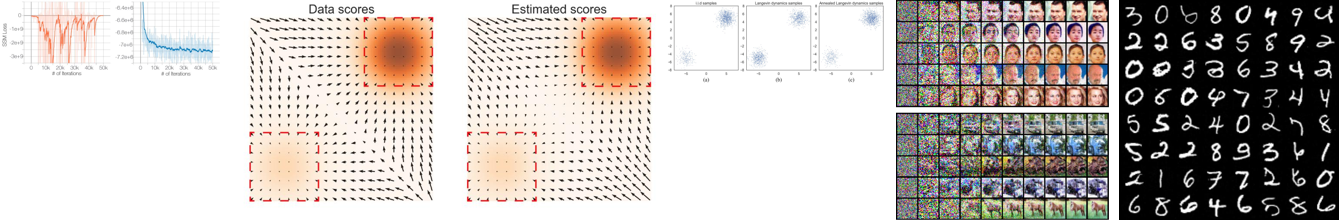

In [34]:
# ============================================================
# [6] 추출 결과 확인 — 그림 (FashionRAG show_image_grid)
# ============================================================
def show_image_grid(paths, thumb=220):
    """여러 이미지를 가로로 이어 붙인 '썸네일 한 장'으로 출력합니다."""
    imgs = [Image.open(p).convert("RGB") for p in paths]
    for im in imgs:
        im.thumbnail((thumb, thumb))
    # 가로로 나란히 붙일 빈 캔버스 생성 (흰 배경, 이미지 사이 10px 여백)
    canvas = Image.new("RGB", (sum(im.width for im in imgs) + 10 * (len(imgs) - 1),
                               max(im.height for im in imgs)), "white")
    x = 0
    for im in imgs:
        canvas.paste(im, (x, 0))
        x += im.width + 10
    display(canvas)


print([f"p.{i['page']}" for i in images[:6]])
show_image_grid([i["image_path"] for i in images[:6]])

---
# Part 3. 2단계 요약 — 검색용 색인 만들기

- 텍스트·표: `ChatPromptTemplate | ChatOpenAI | StrOutputParser` (LCEL)
- 그림: 같은 LCEL 체인의 user 메시지에 `data:image/jpeg;base64,...` 이미지 블록을 넣어 비전 모델로 요약
- 논문이 영어이므로 **요약 프롬프트와 요약도 영어**로 만듭니다 (질문은 Part 5의 번역 체인으로 영어로 바꿈)

- 요약이 곧 검색 색인이므로 **수치·설정값을 빠짐없이** 남기도록 지시합니다. 표는 모든 행의 모든 열 값을 나열하게 합니다.
- 그림은 캡션이 본문 쪽에 있으므로, **같은 페이지의 본문을 함께 넣어** 그림 번호와 표시(빨간 사각형 등)의 의미까지 요약하게 합니다.

> 결과는 `data/processed/summaries.pkl`에 저장해 API 비용을 다시 쓰지 않게 합니다.

In [35]:
# ============================================================
# [7] 요약 실행 (저장본이 있으면 불러옴)
# ============================================================
SUMMARY_PKL = PROCESSED_DIR / "summaries.pkl"

if SUMMARY_PKL.exists() and not REBUILD:
    summaries = load_pickle(SUMMARY_PKL)
    print("저장본 불러옴:", SUMMARY_PKL)
else:
    start = time.time()
    # 그림마다 같은 페이지의 본문(캡션 포함)을 함께 전달
    image_contexts = ["\n\n".join(t["content"] for t in texts if t["page"] == img["page"])
                      for img in images]
    summaries = {
        "texts":  summarize_elements(texts,  model=SUMMARY_MODEL),
        "tables": summarize_elements(tables, model=SUMMARY_MODEL),
        "images": summarize_images(images, image_contexts, model=SUMMARY_MODEL),
    }
    save_pickle(summaries, SUMMARY_PKL)
    print(f"요약 완료 — {time.time() - start:.1f}초 소요")

text_summaries, table_summaries, image_summaries = summaries["texts"], summaries["tables"], summaries["images"]
print(f"텍스트 요약 {len(text_summaries)}개 / 표 요약 {len(table_summaries)}개 / 그림 요약 {len(image_summaries)}개")

저장본 불러옴: C:\workspaces\multimodal-rag\data\processed\summaries.pkl
텍스트 요약 21개 / 표 요약 3개 / 그림 요약 24개


In [37]:
# ============================================================
# [8] 요약 결과 확인
# ============================================================
print(f"[텍스트 요약 p.{texts[0]['page']}]\n{text_summaries[0]}\n")
for t, s in zip(tables, table_summaries):
    print(f"[표 요약 p.{t['page']}]\n{s}\n")
for img, s in list(zip(images, image_summaries))[:4]:
    print(f"[그림 요약 {Path(img['image_path']).name}]\n{s}\n")

[텍스트 요약 p.1]
The text provided does not contain any specific details, numbers, hyperparameters, experimental settings, dataset names, model names, or figure/table references. It appears to be a citation or reference to a research paper titled "Generative Modeling by Estimating Gradients of the Data Distribution," published in 2020. The text includes some formatting artifacts and does not provide substantive content for summarization. Therefore, a detailed summary cannot be constructed from the given information.

[표 요약 p.1]
The table appears to contain contact information for individuals associated with a research paper, specifically email addresses.

Here are the rows with their values:

- Row 1: angsong@cs.stanford.edu, , , , ermon@cs.stanford.edi

[표 요약 p.4]
The table compares various models and their corresponding metrics, likely related to performance or evaluation criteria in a research context.

Here are the rows with the values of all columns:

1. **eee**: Km: , Qt: , astetttte

---
# Part 4. 3단계 검색기 — 요약으로 찾고 원본을 돌려받기 (rag-parser)

| 저장소 | 넣는 것 | 역할 |
|---|---|---|
| `vectorstore` (Chroma) | 요약 임베딩 + 텍스트·표 원문 임베딩 | 검색 대상 |
| `docstore` (InMemoryStore) | 원본: 텍스트, 표 HTML, 그림 base64 | 답변 재료 |

`MultiVectorRetriever`가 검색 결과의 `doc_id`로 원본을 꺼내 돌려줍니다.

- 원본 하나에 벡터를 **여러 개**(요약 + 원문) 연결합니다. 요약에서 빠진 세부 수치도 원문 벡터로 검색되게 하기 위함입니다.
- 같은 `doc_id`가 여러 번 걸려도 원본은 한 번만 돌려줍니다.

In [38]:
# ============================================================
# [9] 다중 벡터 검색기 생성 & 검색 테스트
# ============================================================
mm_retriever = create_multi_vector_retriever(
    [(texts, text_summaries), (tables, table_summaries), (images, image_summaries)],
    k=N_RESULTS,
)

# '요약'으로 찾았지만 돌려받는 것은 '원본'입니다.
docs = mm_retriever.invoke("Inception and FID scores of NCSN on CIFAR-10")
for d in docs:
    kind, page = d.metadata["kind"], d.metadata["page"]
    preview = "(그림 base64 원본)" if kind == "image" else d.page_content[:120].replace("\n", " ")
    print(f"[{kind} p.{page}] {preview}")

[table p.7] <table><tr><td>Model</td><td>Inception</td><td>FID</td></tr><tr><td colspan="3">CIFAR-10 Unconditional</td></tr><tr><td>
[text p.15] B Additional experimental details  B.1 Toy experiments  For the results in Fig. 1, we train a ResNet with sliced score m
[text p.7] 5 Experiments  In this section, we demonstrate that our NCSNs are able to produce high quality image samples on several 


---
# Part 5. LangChain 체인 — 번역 체인 & RAG 체인 (FashionRAG)

```
 {"text": ..., "target_lang": ...}  ─ ChatPromptTemplate ─▶ [System, Human] ─ ChatOpenAI ─▶ AIMessage ─ StrOutputParser ─▶ str
```

In [39]:
# ============================================================
# [10] 번역 체인 (LCEL: 프롬프트 | 모델 | 파서)
# ============================================================
# temperature=0.0 : 번역처럼 '정답에 가까운 출력'이 필요할 때 무작위성 최소화
translation_model = ChatOpenAI(model=TRANSLATION_MODEL, temperature=0.0)

translation_prompt = ChatPromptTemplate.from_messages([
    ("system", "Translate the following text into {target_lang}. "
               "Keep technical terms, model names and numbers as they are. "
               "Output only the translation."),
    ("user", "{text}"),
])

translation_chain = translation_prompt | translation_model | StrOutputParser()


def translate(text, target_lang):
    """text 를 target_lang(예: 'English', 'Korean')으로 번역한 문자열을 반환합니다."""
    return translation_chain.invoke({"text": text, "target_lang": target_lang})


print(translate("Table 1에서 NCSN의 FID는 얼마인가요?", "English"))

What is the FID of NCSN in Table 1?


In [41]:
# ============================================================
# [11] RAG 체인: 원본 텍스트·표 + 그림을 함께 LLM 에 전달
# ============================================================
def setup_rag_chain():
    """논문 질의응답용 '프롬프트 | 비전모델 | 파서' 체인을 반환합니다."""
    rag_model = ChatOpenAI(model=RAG_MODEL, temperature=0.0)

    # system : 모델의 역할 — 제공된 근거로만 답하고, 근거가 없으면 없다고 말하기
    # user   : 질문 + 원본 텍스트·표(context)
    # image_messages : 검색된 그림을 data URL 이미지 블록으로 담은 메시지 (없으면 비어 있음)
    rag_prompt = ChatPromptTemplate.from_messages([
        ("system",
         "You are an assistant answering questions about a machine learning research paper. "
         "Answer only from the provided context: text passages, tables (HTML) and figures. "
         "Keep numbers and model names exactly as written. "
         "The text was extracted from a PDF, so symbols may be broken by OCR "
         "(e.g. 'σ' may appear as 'o' or '0', subscripts may be flattened). "
         "For figures, use both the attached image and its description. "
         "If the context is not enough, say \"The provided context does not contain the answer.\""),
        ("user", "Question: {user_query}\n\nContext:\n{context}"),
        MessagesPlaceholder("image_messages", optional=True),
    ])
    return rag_prompt | rag_model | StrOutputParser()


def format_prompt_inputs(docs, user_query):
    """검색된 원본 문서와 질문으로 RAG 프롬프트 입력 dict 를 만듭니다."""
    context_parts, image_blocks = [], []
    for d in docs:
        kind, page = d.metadata["kind"], d.metadata.get("page")
        tag = f"[{kind} p.{page}]" if page else f"[{kind}]"
        if kind == "image":
            context_parts.append(f"{tag} (attached figure) description: {d.metadata.get('summary', '')}")
            image_blocks.append({"type": "image_url",
                                 "image_url": {"url": f"data:image/jpeg;base64,{d.page_content}"}})
        else:
            context_parts.append(f"{tag}\n{d.page_content}")

    return {
        "user_query": user_query,
        "context": "\n\n".join(context_parts),
        "image_messages": [HumanMessage(content=image_blocks)] if image_blocks else [],
    }


def sources(docs):
    """'table p.7, image p.4' 형태로 근거 원본의 종류와 페이지를 적습니다."""
    return ", ".join(f"{d.metadata['kind']} p.{d.metadata['page']}" if d.metadata.get("page")
                     else d.metadata["kind"] for d in docs)


rag_chain = setup_rag_chain()
print("RAG 체인 준비 완료")

RAG 체인 준비 완료


---
# Part 6. 전체 파이프라인 & 질의응답 5건

| 단계 | 함수 | RAG 역할 |
|---|---|---|
| ① 질문 번역 | `translate(query_ko, "English")` | 전처리 |
| ② 검색 | `retriever.invoke(query_en)` | **R**etrieval |
| ③ 프롬프트 입력 구성 | `format_prompt_inputs(docs, query_en)` | **A**ugmentation |
| ④ 답변 생성 | `rag_chain.invoke(prompt_input)` | **G**eneration |
| ⑤ 답변 번역 | `translate(answer_en, "Korean")` | 후처리 |

In [42]:
# ============================================================
# [12] 전체 파이프라인: 한국어 질문 -> 번역 -> 검색 -> RAG 체인 -> 번역 -> 출력
# ============================================================
def ask_paper_rag(query_ko, retriever, show=True):
    """한국어 질문 하나를 받아 전체 과정을 실행하고 결과 dict 를 반환합니다."""
    query_en = translate(query_ko, "English")                 # ①
    docs = retriever.invoke(query_en)                         # ②
    prompt_input = format_prompt_inputs(docs, query_en)       # ③
    answer_en = rag_chain.invoke(prompt_input)                # ④
    answer_ko = translate(answer_en, "Korean")                # ⑤

    if show:
        print("질문        :", query_ko)
        print("번역된 질문 :", query_en)
        print("근거 원본   :", sources(docs))
        display(Markdown(answer_ko))
        image_paths = [d.metadata["image_path"] for d in docs if d.metadata["kind"] == "image"]
        if image_paths:
            show_image_grid(image_paths)

    return {"query_ko": query_ko, "query_en": query_en, "docs": docs,
            "answer_en": answer_en, "answer_ko": answer_ko, "sources": sources(docs)}


============================== Q1 ==============================
질문        : CIFAR-10 unconditional 설정에서 NCSN의 Inception score와 FID는 각각 얼마인가요?
번역된 질문 : What are the Inception score and FID of NCSN in the CIFAR-10 unconditional setting?
근거 원본   : table p.7, text p.13, text p.15, text p.7


CIFAR-10 무조건 설정에서 NCSN의 Inception 점수는 8.87+.12이며, FID 점수는 25.32입니다.


============================== Q2 ==============================
질문        : Table 1에서 Inception score가 NCSN보다 높은 모델은 무엇이고, 어떤 설정인가요?
번역된 질문 : Which model in Table 1 has a higher Inception score than NCSN, and what is the setting?
근거 원본   : table p.7, text p.13, text p.6, text p.7


표 1에서 NCSN보다 높은 Inception 점수를 가진 모델은 BigGAN으로, Inception 점수는 9.22입니다. 이 점수의 설정은 "CIFAR-10 Conditional"입니다.


============================== Q3 ==============================
질문        : Figure 2에서 빨간 사각형으로 표시된 영역은 무엇을 의미하나요?
번역된 질문 : What does the area marked with a red rectangle in Figure 2 represent?
근거 원본   : image p.16, image p.16, image p.4, image p.16, image p.4, image p.16


그림 2에서 빨간 직사각형으로 표시된 영역은 추정된 점수가 실제 점수와 밀접하게 근접하는 지역을 나타내며, 특히 데이터 밀도가 높은 영역에서 그렇습니다. 이는 점수 추정이 주로 데이터 분포의 모드 근처, 즉 밀도가 높은 곳에서 신뢰할 수 있음을 강조합니다.

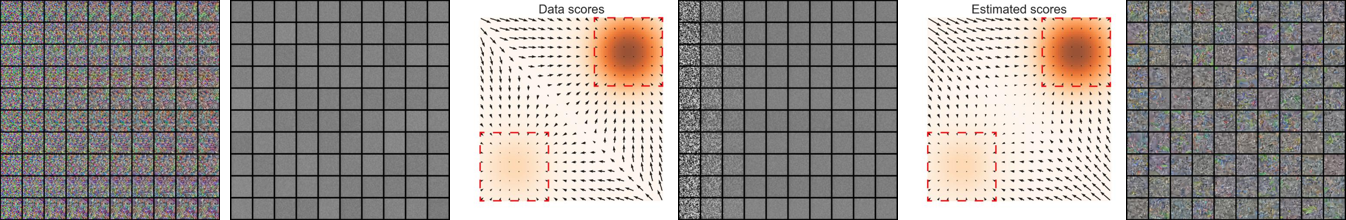


============================== Q4 ==============================
질문        : Figure 3에서 annealed Langevin dynamics와 일반 Langevin dynamics의 결과는 어떻게 다른가요?
번역된 질문 : How do the results of annealed Langevin dynamics differ from those of regular Langevin dynamics in Figure 3?
근거 원본   : text p.7, image p.5, text p.4, image p.7


어닐링된 랑주뱅 역학의 결과는 일반 랑주뱅 역학의 결과와 다음과 같이 다릅니다:

1. **샘플의 분포**:
   - **일반 랑주뱅 역학 (그림 3(b))**: 샘플은 주로 한 지역(왼쪽 하단 사분면)에 집중되어 있어 두 모드의 실제 분포를 포착하지 못하고 있습니다. 이로 인해 모드 간의 상대적인 가중치가 잘못됩니다.
   - **어닐링된 랑주뱅 역학 (그림 3(c))**: 샘플은 두 모드에 걸쳐 보다 고르게 분포되어 있어 상대적인 가중치를 정확하게 반영하고, 목표 분포에 대한 혼합 및 수렴이 개선된 것을 보여줍니다.

2. **샘플링 품질**:
   - 어닐링된 랑주뱅 역학은 목표 분포의 특성을 효과적으로 회복하는 반면, 일반 랑주뱅 역학은 특히 모드 간의 낮은 밀도 지역에서 이를 수행하는 데 어려움을 겪습니다.

요약하자면, 어닐링된 랑주뱅 역학은 일반 랑주뱅 역학에 비해 기본 분포를 보다 균형 잡히고 정확하게 표현하며, 일반 랑주뱅 역학은 모드의 상대 밀도를 잘못 표현하는 경향이 있습니다.

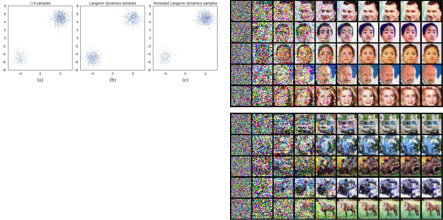


============================== Q5 ==============================
질문        : 이미지 생성 실험에서 노이즈 수준 σ는 몇 개, 어떤 범위로 설정했나요?
번역된 질문 : In the image generation experiment, how many noise levels σ were set, and what range were they in?
근거 원본   : text p.5, text p.7, text p.15


이미지 생성 실험에서는 10가지의 서로 다른 노이즈 수준 σ가 설정되었으며, σ₀ = 1에서 σ₉ = 0.01까지 범위가 지정되었습니다.

In [43]:
# ============================================================
# [13] 질의응답 5건
# ============================================================
QUESTIONS = [
    "CIFAR-10 unconditional 설정에서 NCSN의 Inception score와 FID는 각각 얼마인가요?",
    "Table 1에서 Inception score가 NCSN보다 높은 모델은 무엇이고, 어떤 설정인가요?",
    "Figure 2에서 빨간 사각형으로 표시된 영역은 무엇을 의미하나요?",
    "Figure 3에서 annealed Langevin dynamics와 일반 Langevin dynamics의 결과는 어떻게 다른가요?",
    "이미지 생성 실험에서 노이즈 수준 σ는 몇 개, 어떤 범위로 설정했나요?",
]

mm_results = []
for i, q in enumerate(QUESTIONS, start=1):
    print(f"\n{'=' * 30} Q{i} {'=' * 30}")
    mm_results.append(ask_paper_rag(q, mm_retriever))

In [44]:
# ============================================================
# [14] README 에 붙여 넣을 질의응답 표
# ============================================================
def one_line(s):
    return s.replace("\n", " ").replace("|", "\\|")

print("| # | 질문 | 답변 | 근거가 된 원본 종류 |")
print("| --- | --- | --- | --- |")
for i, r in enumerate(mm_results, start=1):
    kinds = ", ".join(sorted({d.metadata["kind"] for d in r["docs"]}))
    print(f"| {i} | {one_line(r['query_ko'])} | {one_line(r['answer_ko'])} | {kinds} ({r['sources']}) |")

| # | 질문 | 답변 | 근거가 된 원본 종류 |
| --- | --- | --- | --- |
| 1 | CIFAR-10 unconditional 설정에서 NCSN의 Inception score와 FID는 각각 얼마인가요? | CIFAR-10 무조건 설정에서 NCSN의 Inception 점수는 8.87+.12이며, FID 점수는 25.32입니다. | table, text (table p.7, text p.13, text p.15, text p.7) |
| 2 | Table 1에서 Inception score가 NCSN보다 높은 모델은 무엇이고, 어떤 설정인가요? | 표 1에서 NCSN보다 높은 Inception 점수를 가진 모델은 BigGAN으로, Inception 점수는 9.22입니다. 이 점수의 설정은 "CIFAR-10 Conditional"입니다. | table, text (table p.7, text p.13, text p.6, text p.7) |
| 3 | Figure 2에서 빨간 사각형으로 표시된 영역은 무엇을 의미하나요? | 그림 2에서 빨간 직사각형으로 표시된 영역은 추정된 점수가 실제 점수와 밀접하게 근접하는 지역을 나타내며, 특히 데이터 밀도가 높은 영역에서 그렇습니다. 이는 점수 추정이 주로 데이터 분포의 모드 근처, 즉 밀도가 높은 곳에서 신뢰할 수 있음을 강조합니다. | image (image p.16, image p.16, image p.4, image p.16, image p.4, image p.16) |
| 4 | Figure 3에서 annealed Langevin dynamics와 일반 Langevin dynamics의 결과는 어떻게 다른가요? | 어닐링된 랑주뱅 역학의 결과는 일반 랑주뱅 역학의 결과와 다음과 같이 다릅니다:  1. **샘플의 분포**:    - **일반 랑주뱅 역학 (그림 3(b))**: 샘플은 주로 한 지역(왼쪽 하단 사분면)에 집중되어 있어 두 모드의 실제 분포를 포착하지 못하고 있습니다. 이로 인해

---
# Part 7. Before / After — 텍스트 RAG vs 멀티모달 RAG

| 구분 | 검색 대상 | 답변 재료 |
|---|---|---|
| **Before (텍스트 RAG)** | 텍스트를 2000토큰 / overlap 200으로 자른 청크 원문 (수업 01 [8]) | 텍스트 청크만 |
| **After (멀티모달 RAG)** | 텍스트·표·그림 요약 + 텍스트·표 원문 | 원본 텍스트 · 표 HTML · 그림 |

번역 체인, RAG 체인, `N_RESULTS`는 같고 **검색 대상만** 다릅니다.

In [46]:
# ============================================================
# [15] Before: 텍스트만 쓰는 RAG 로 같은 질문 실행 & 비교
# ============================================================
import importlib, src.extract, src.retriever
importlib.reload(src.extract); importlib.reload(src.retriever)

from src.extract import split_texts
from src.retriever import create_text_retriever

texts_2k_token = split_texts(texts)    # 수업 01 [8]: 2000토큰 / overlap 200
print("텍스트 청크 수:", len(texts_2k_token))

text_retriever = create_text_retriever(texts_2k_token, k=N_RESULTS)
text_results = [ask_paper_rag(q, text_retriever, show=False) for q in QUESTIONS]

for i, (before, after) in enumerate(zip(text_results, mm_results), start=1):
    print(f"\n{'=' * 30} Q{i} {'=' * 30}")
    print("질문:", before["query_ko"])
    print(f"\n[Before 텍스트 RAG]   근거: {before['sources']}")
    print(before["answer_ko"])
    print(f"\n[After 멀티모달 RAG]  근거: {after['sources']}")
    print(after["answer_ko"])

텍스트 청크 수: 9

============================== Q1 ==============================
질문: CIFAR-10 unconditional 설정에서 NCSN의 Inception score와 FID는 각각 얼마인가요?

[Before 텍스트 RAG]   근거: text, text, text, text, text, text
CIFAR-10 무조건 설정에서 NCSN은 8.87의 Inception 점수와 25.32의 FID 점수를 달성합니다.

[After 멀티모달 RAG]  근거: table p.7, text p.13, text p.15, text p.7
CIFAR-10 무조건 설정에서 NCSN의 Inception 점수는 8.87+.12이며, FID 점수는 25.32입니다.

============================== Q2 ==============================
질문: Table 1에서 Inception score가 NCSN보다 높은 모델은 무엇이고, 어떤 설정인가요?

[Before 텍스트 RAG]   근거: text, text, text, text, text, text
제공된 맥락에는 답이 포함되어 있지 않습니다.

[After 멀티모달 RAG]  근거: table p.7, text p.13, text p.6, text p.7
표 1에서 NCSN보다 높은 Inception 점수를 가진 모델은 BigGAN으로, Inception 점수는 9.22입니다. 이 점수의 설정은 "CIFAR-10 Conditional"입니다.

============================== Q3 ==============================
질문: Figure 2에서 빨간 사각형으로 표시된 영역은 무엇을 의미하나요?

[Before 텍스트 RAG]   근거: text, text, text, text, text, text
그림 2에서 빨간 사각형으로 표시된 영역은 데이터 밀도의 기울기 ∇x log 

In [48]:
# ============================================================
# [16] README 에 붙여 넣을 Before / After 비교 표
# ============================================================
print("| # | 질문 | Before (텍스트 RAG) | After (멀티모달 RAG) |")
print("| --- | --- | --- | --- |")
for i, (b, a) in enumerate(zip(text_results, mm_results), start=1):
    a_kinds = ", ".join(sorted({d.metadata["kind"] for d in a["docs"]}))
    print(f"| {i} | {one_line(b['query_ko'])} | {one_line(b['answer_ko'])} (근거: text) "
          f"| {one_line(a['answer_ko'])} (근거: {a_kinds}) |")

| # | 질문 | Before (텍스트 RAG) | After (멀티모달 RAG) |
| --- | --- | --- | --- |
| 1 | CIFAR-10 unconditional 설정에서 NCSN의 Inception score와 FID는 각각 얼마인가요? | CIFAR-10 무조건 설정에서 NCSN은 8.87의 Inception 점수와 25.32의 FID 점수를 달성합니다. (근거: text) | CIFAR-10 무조건 설정에서 NCSN의 Inception 점수는 8.87+.12이며, FID 점수는 25.32입니다. (근거: table, text) |
| 2 | Table 1에서 Inception score가 NCSN보다 높은 모델은 무엇이고, 어떤 설정인가요? | 제공된 맥락에는 답이 포함되어 있지 않습니다. (근거: text) | 표 1에서 NCSN보다 높은 Inception 점수를 가진 모델은 BigGAN으로, Inception 점수는 9.22입니다. 이 점수의 설정은 "CIFAR-10 Conditional"입니다. (근거: table, text) |
| 3 | Figure 2에서 빨간 사각형으로 표시된 영역은 무엇을 의미하나요? | 그림 2에서 빨간 사각형으로 표시된 영역은 데이터 밀도의 기울기 ∇x log pdata(x)가 추정된 점수 sθ(x)와 대략적으로 같음을 나타내는 지역을 의미합니다. 이는 점수 추정이 이러한 지역에서 신뢰할 수 있음을 나타내며, 이러한 지역은 일반적으로 데이터 밀도가 높은 데이터 분포의 모드 근처에 위치합니다. (근거: text) | 그림 2에서 빨간 직사각형으로 표시된 영역은 추정된 점수가 실제 점수와 밀접하게 근접하는 지역을 나타내며, 특히 데이터 밀도가 높은 영역에서 그렇습니다. 이는 점수 추정이 주로 데이터 분포의 모드 근처, 즉 밀도가 높은 곳에서 신뢰할 수 있음을 강조합니다. (근거: image) |
| 4 | Figure 3에서 annealed Langevin dynamics와 일반 Langevin dyn